# 选股窗口研究 第二版：只在同一细分行业内配对

```
2010 ........ 2020 | 2021  2022  2023 | 2024  2025  2026
     选股数据        |      验证         |       测试
```

**第二版和第一版的区别**
1. **只在同一个 GICS 细分行业（sub-industry）内配对**，比如两家电力公司、两家财险公司。检验对数从约 9 万降到约 1 千，BH 门槛宽松约 90 倍，而且配对有经济逻辑。
2. **增加"估计窗口 = 选股窗口"的选项**：在哪段时间验证了协整，就用哪段时间估计 β。
3. **剔除对冲比例异常的配对**：美元对冲比例（β × B价格 / A价格）不在 0.25 到 4 之间的配对-年份不交易（第一版 OXY–SWKS 在 2024 年的 β = −0.04，等于没对冲）。
4. 结果存到新文件夹 `selection_window_study_outputs_v2/`，**第一版的结果不会被覆盖**。

注意：行业分类用的是现在的 GICS 分类（`sp500_gics.csv`），回溯到 2010 年时有些公司的分类可能不同，报告里要说明。

**思路（和第一版相同）**
1. 验证：用截至 2020 年的 1/3/5/10 年数据分别选股，在 2021–23 上比较各种参数。
2. 只根据验证结果选出一组参数，然后**冻结**。
3. 测试：用同样的选股规则、截至 2023 年的数据重新选股，在 2024–26 上**只跑一次**。

**运行前准备**
- 这个 notebook 要放在项目根目录，和 `selection_window_study.py`、`pairs_backtest_engine.py` 在同一个文件夹。
- 从上到下一个 cell 一个 cell 运行（Shift + Enter）。
- 所有函数都写在 `selection_window_study.py` 里，这样多进程在 Mac 上才能正常工作。notebook 只负责一步步调用。

## 第 0 步：导入和检查文件
确认当前文件夹对不对，引擎文件和数据文件在不在。

In [1]:
import importlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import selection_window_study as sws
importlib.reload(sws)   # 如果改过 .py 文件，重新运行这个 cell 就会生效

print("当前文件夹:", Path.cwd())
assert Path("pairs_backtest_engine.py").exists(), "找不到 pairs_backtest_engine.py，notebook 要放在项目根目录"
assert sws.DATA_FILE.exists(), f"找不到数据文件 {sws.DATA_FILE}"
print("文件检查通过")

当前文件夹: /Users/liusiming/pairs-trading-strategy
文件检查通过


## 第 1 步：设置参数
- `SELECTION_WINDOWS`：**选股窗口**，用几年数据做协整检验，决定"交易哪几对"。
- `ESTIMATION_WINDOWS`：**滚动窗口**，每个交易年开始前用前几年数据估计 α、β 和 spread 的均值、标准差（z 值要用），决定"这一对怎么交易"。
- 其余是交易规则：entry、exit、止损、最长持仓。

这里列出的所有组合**只在验证集 2021–23 上比较**。想加窗口直接改列表，但组合越多越容易过拟合。

In [2]:
# ---- 第二版设置 ----
sws.PAIR_UNIVERSE = "sub_industry"          # "all" = 第一版；"sector" = 同一大行业
sws.EST_SAME_AS_SELECTION = True            # 增加 估计窗口 = 选股窗口 的选项
sws.MIN_DOLLAR_HEDGE = 0.25                 # 美元对冲比例要在 [0.25, 4] 之间
sws.OUTPUT_DIR = Path("selection_window_study_outputs_v2")
assert sws.GICS_FILE.exists(), "找不到 sp500_gics.csv"

sws.SELECTION_WINDOWS  = [1, 3, 5, 10]
sws.ESTIMATION_WINDOWS = [1, 2, 3, 5]
sws.ENTRY_Z  = [1.5, 2.0, 2.5]
sws.EXIT_Z   = [0.0, 0.5]
sws.STOP_Z   = [None, 3.0]
sws.MAX_HOLD = [None, 60]

COST = 0.001                     # 单边交易成本 10bp
VALIDATION_CUTOFF, VALIDATION_YEARS = 2020, [2021, 2022, 2023]
TEST_CUTOFF, TEST_YEARS = 2023, [2024, 2025, 2026]
MIN_VALIDATION_TRADES = 10       # 交易数少于这个的组合不参与挑选

OUT = sws.OUTPUT_DIR
OUT.mkdir(exist_ok=True)
print("验证阶段参数组合数:", len(sws.grid_combos()))

验证阶段参数组合数: 408


## 第 2 步：读取价格数据

In [3]:
prices = sws.load_prices()
print("形状:", prices.shape)
print("日期:", prices.index.min().date(), "到", prices.index.max().date())
display(prices.iloc[:5, :5])

形状: (4245, 485)
日期: 2010-01-04 到 2026-11-17


,A,AAPL,ABBV,ABT,ACGL
Date,,,,,
2010-01-04,19.743519,6.396101,NaN,17.968191,7.601905
2010-01-05,19.529053,6.407160,NaN,17.823011,7.576549
2010-01-06,19.459665,6.305244,NaN,17.922005,7.543795
2010-01-07,19.434433,6.293589,NaN,18.070469,7.499420
2010-01-08,19.428129,6.335429,NaN,18.162849,7.484628


## 第 3 步：验证阶段选股（最慢的一步）
对每个选股窗口（数据都截至 2020-12-31）做三件事：
1. 先对每只股票单独做 ADF 检验，只保留 I(1) 的股票（剔除本身就横盘、平稳的股票）。
2. 对剩下的所有配对做 Engle-Granger 协整检验，多核并行。
3. 做 BH-FDR 校正。

第二版每个窗口只检验约 1 千对，**每个窗口一两分钟就能跑完**。

In [4]:
val_screens = {}
for s in sws.SELECTION_WINDOWS:
    val_screens[s] = sws.screen(prices, VALIDATION_CUTOFF, s)

summary = pd.DataFrame([{
    "选股窗口": f"{s}Y",
    "检验配对数": len(df),
    "原始 p<0.01": int((df["P Value"] < 0.01).sum()),
    "原始 p<0.05": int((df["P Value"] < 0.05).sum()),
    "BH 显著": int(df["BH Significant"].sum()),
} for s, df in val_screens.items()])
display(summary)

[cut2020_1Y] window 2020-2020: 253 days, 425 tickers, universe=sub_industry, 1,006 pairs, 1,006 to test
[cut2020_1Y] 500/1,006 elapsed 7s
[cut2020_1Y] 1,000/1,006 elapsed 7s
[cut2020_1Y] 1,006/1,006 elapsed 7s
[cut2020_1Y] BH-significant pairs: 5
[cut2020_3Y] window 2018-2020: 756 days, 427 tickers, universe=sub_industry, 1,068 pairs, 1,068 to test
[cut2020_3Y] 500/1,068 elapsed 10s
[cut2020_3Y] 1,000/1,068 elapsed 10s
[cut2020_3Y] 1,068/1,068 elapsed 10s
[cut2020_3Y] BH-significant pairs: 0
[cut2020_5Y] window 2016-2020: 1259 days, 416 tickers, universe=sub_industry, 1,046 pairs, 1,046 to test
[cut2020_5Y] 500/1,046 elapsed 15s
[cut2020_5Y] 1,000/1,046 elapsed 15s
[cut2020_5Y] 1,046/1,046 elapsed 15s
[cut2020_5Y] BH-significant pairs: 3
[cut2020_10Y] window 2011-2020: 2517 days, 426 tickers, universe=sub_industry, 1,072 pairs, 1,072 to test
[cut2020_10Y] 500/1,072 elapsed 43s
[cut2020_10Y] 1,000/1,072 elapsed 43s
[cut2020_10Y] 1,072/1,072 elapsed 43s
[cut2020_10Y] BH-significant pairs

,选股窗口,检验配对数,原始 p<0.01,原始 p<0.05,BH 显著
0,1Y,1006,28,80,5
1,3Y,1068,21,74,0
2,5Y,1046,25,78,3
3,10Y,1072,34,102,3


## 第 4 步：确定每个窗口要交易的配对
规则：先取 BH 显著的配对；如果不到 5 对，就按原始 p 值从小到大补满 10 对，补进来的标注 **Top-p fill (not BH-significant)**。每只股票最多出现在一对里。

In [5]:
val_pairs = {}
for s in sws.SELECTION_WINDOWS:
    chosen = sws.pick_pairs(val_screens[s])
    chosen.to_csv(OUT / f"validation_pairs_{s}Y.csv", index=False)
    val_pairs[s] = list(zip(chosen["Ticker A"], chosen["Ticker B"]))
    print(f"\n===== {s}Y：{len(chosen)} 对 =====")
    display(chosen[["Ticker A", "Ticker B", "Sub-Industry A", "P Value", "BH Adjusted P", "Selection Basis"]])


===== 1Y：5 对 =====


,Ticker A,Ticker B,Sub-Industry A,P Value,BH Adjusted P,Selection Basis
0,FSLR,QCOM,Semiconductors,0.000039,0.025857,BH-significant
1,AVY,IP,Paper & Plastic Packaging Products & Materials,0.000063,0.025857,BH-significant
2,INTU,TRMB,Application Software,0.000077,0.025857,BH-significant
3,TDG,TXT,Aerospace & Defense,0.000107,0.027019,BH-significant
4,DHR,TMO,Life Sciences Tools & Services,0.000145,0.029111,BH-significant



===== 3Y：10 对 =====


,Ticker A,Ticker B,Sub-Industry A,P Value,BH Adjusted P,Selection Basis
0,ISRG,RVTY,Health Care Equipment,0.000177,0.188537,Top-p fill (not BH-significant)
1,ES,WEC,Electric Utilities,0.001745,0.408810,Top-p fill (not BH-significant)
2,CFG,FITB,Regional Banks,0.001935,0.408810,Top-p fill (not BH-significant)
3,KLAC,TER,Semiconductor Materials & Equipment,0.002315,0.408810,Top-p fill (not BH-significant)
4,APA,EOG,Oil & Gas Exploration & Production,0.002886,0.408810,Top-p fill (not BH-significant)
5,CPRT,CTAS,Diversified Support Services,0.003259,0.408810,Top-p fill (not BH-significant)
6,PODD,RMD,Health Care Equipment,0.004221,0.408810,Top-p fill (not BH-significant)
7,D,PCG,Multi-Utilities,0.005274,0.408810,Top-p fill (not BH-significant)
8,NSC,UNP,Rail Transportation,0.005447,0.408810,Top-p fill (not BH-significant)
9,DG,WMT,Consumer Staples Merchandise Retail,0.005505,0.408810,Top-p fill (not BH-significant)



===== 5Y：10 对 =====


,Ticker A,Ticker B,Sub-Industry A,P Value,BH Adjusted P,Selection Basis
0,MRSH,WTW,Insurance Brokers,0.000063,0.037829,BH-significant
1,ABT,STE,Health Care Equipment,0.000081,0.037829,BH-significant
2,PODD,RMD,Health Care Equipment,0.000108,0.037829,BH-significant
3,LRCX,TER,Semiconductor Materials & Equipment,0.000639,0.156417,Top-p fill (not BH-significant)
4,MRK,VTRS,Pharmaceuticals,0.000748,0.156417,Top-p fill (not BH-significant)
5,CPRT,CTAS,Diversified Support Services,0.000988,0.172310,Top-p fill (not BH-significant)
6,MA,V,Transaction & Payment Processing Services,0.001310,0.176768,Top-p fill (not BH-significant)
7,CCI,SBAC,Telecom Tower REITs,0.001522,0.176768,Top-p fill (not BH-significant)
8,EOG,FANG,Oil & Gas Exploration & Production,0.001690,0.176768,Top-p fill (not BH-significant)
9,LNT,WEC,Electric Utilities,0.002468,0.234709,Top-p fill (not BH-significant)



===== 10Y：10 对 =====


,Ticker A,Ticker B,Sub-Industry A,P Value,BH Adjusted P,Selection Basis
0,ES,WEC,Electric Utilities,0.000012,0.013169,BH-significant
1,ACGL,CINF,Property & Casualty Insurance,0.000041,0.022016,BH-significant
2,CDNS,SNPS,Application Software,0.000068,0.024123,BH-significant
3,ABT,RMD,Health Care Equipment,0.000459,0.092948,Top-p fill (not BH-significant)
4,TECH,TMO,Life Sciences Tools & Services,0.000509,0.092948,Top-p fill (not BH-significant)
5,EIX,PPL,Electric Utilities,0.000537,0.092948,Top-p fill (not BH-significant)
6,CRH,MLM,Construction Materials,0.000607,0.092948,Top-p fill (not BH-significant)
7,BDX,BSX,Health Care Equipment,0.000825,0.110548,Top-p fill (not BH-significant)
8,ADI,TXN,Semiconductors,0.001068,0.116572,Top-p fill (not BH-significant)
9,LRCX,TER,Semiconductor Materials & Equipment,0.001144,0.116572,Top-p fill (not BH-significant)


## 第 5 步：验证集参数网格（2021–2023）
对每个组合，在 2021、2022、2023 三年里逐年交易：每年开始前用前 N 年数据重新估计 β，这一年内参数不变。组合收益 = 各配对等权平均。

In [6]:
validation = sws.validation_grid(prices, val_pairs, VALIDATION_YEARS, cost=COST)
validation.to_csv(OUT / "validation_grid.csv", index=False)
print("完成，共", len(validation), "个组合")

Validation grid 50/408 elapsed 4s
Validation grid 100/408 elapsed 8s
Validation grid 150/408 elapsed 20s
Validation grid 200/408 elapsed 29s
Validation grid 250/408 elapsed 38s
Validation grid 300/408 elapsed 46s
Validation grid 350/408 elapsed 54s
Validation grid 400/408 elapsed 62s
Validation grid 408/408 elapsed 64s
完成，共 408 个组合


## 第 6 步：哪种选股窗口更好？（稳健的看法）
不只看单个最优组合，而是看每种选股窗口在**所有参数组合**下的表现：Sharpe 中位数、Sharpe 为正的组合占比。这张表比"最优组合"更能回答"哪种选股窗口更好"。

In [7]:
by_window = validation.groupby("Selection Window").agg(
    组合数=("Sharpe", "size"),
    Sharpe中位数=("Sharpe", "median"),
    Sharpe为正占比=("Sharpe", lambda x: float((x > 0).mean())),
    年化收益中位数=("Annualized Return (%)", "median"),
    交易数中位数=("Trades", "median"),
).reset_index()
by_window.to_csv(OUT / "validation_by_selection_window.csv", index=False)
display(by_window.round(3))

# 同样的思路看滚动窗口
by_est = validation.groupby("Estimation Window").agg(
    Sharpe中位数=("Sharpe", "median"),
    Sharpe为正占比=("Sharpe", lambda x: float((x > 0).mean())),
).reset_index()
display(by_est.round(3))

,Selection Window,组合数,Sharpe中位数,Sharpe为正占比,年化收益中位数,交易数中位数
0,1,96,-0.679,0.052,-2.652,19.0
1,3,96,-0.039,0.458,-0.161,43.0
2,5,96,0.475,0.812,1.319,44.5
3,10,120,0.332,0.658,0.631,49.0


,Estimation Window,Sharpe中位数,Sharpe为正占比
0,1,-0.239,0.302
1,2,0.189,0.594
2,3,0.169,0.604
3,5,0.043,0.521
4,10,0.047,0.500


## 第 7 步：在验证集上选出参数并冻结
在交易数够多的组合里选 Sharpe 最高的。**从这里开始，这组参数就不再改了。**

注意：这是从几百个组合里挑出的最好一个，所以验证集上的 Sharpe 会偏乐观。测试集的结果才是真正的样本外表现。

In [8]:
eligible = validation[validation["Trades"] >= MIN_VALIDATION_TRADES].dropna(subset=["Sharpe"])
top = eligible.sort_values(["Sharpe", "Annualized Return (%)"], ascending=False)
display(top.head(10).round(3))

params = sws.choose_params(validation, MIN_VALIDATION_TRADES)
(OUT / "chosen_parameters.json").write_text(json.dumps(params, indent=2))
print("冻结的参数:", params)

,Selection Window,Estimation Window,Entry Z,Exit Z,Stop Z,Max Hold,Total Return (%),Annualized Return (%),Volatility (%),Sharpe,Max Drawdown (%),Trades,Win Rate (%),Avg Trade Return (%),Avg Annual Turnover,Top-5 Trades Share of P&L (%),Pair-Years Traded
347,10,3,2.0,0.0,3.0,60.0,6.939,2.271,1.495,1.509,-1.678,43,53.488,1.614,3.034,55.701,30
350,10,3,2.0,0.5,3.0,NaN,7.202,2.355,1.693,1.383,-1.678,48,54.167,1.531,3.326,53.633,30
351,10,3,2.0,0.5,3.0,60.0,5.757,1.891,1.410,1.336,-1.678,46,54.348,1.310,3.177,58.560,30
268,5,5,1.5,0.5,NaN,NaN,14.188,4.540,3.610,1.248,-3.115,85,81.176,1.471,6.726,29.730,27
345,10,3,2.0,0.0,NaN,60.0,8.015,2.614,2.093,1.243,-2.144,43,62.791,1.885,3.051,48.743,30
264,5,5,1.5,0.0,NaN,NaN,14.044,4.496,3.773,1.185,-3.997,67,80.597,1.849,5.314,34.249,27
339,10,3,1.5,0.0,3.0,60.0,6.575,2.154,1.832,1.172,-2.025,58,56.897,1.161,4.070,57.675,30
349,10,3,2.0,0.5,NaN,60.0,6.777,2.219,2.010,1.102,-2.144,46,63.043,1.556,3.192,51.969,30
346,10,3,2.0,0.0,3.0,NaN,6.505,2.132,1.936,1.099,-2.042,43,48.837,1.528,3.026,60.293,30
342,10,3,1.5,0.5,3.0,NaN,6.747,2.209,2.026,1.089,-2.031,70,64.286,0.992,4.819,54.499,30


冻结的参数: {'s': 10, 'n': 3, 'entry': 2.0, 'exit_': 0.0, 'stop': 3.0, 'hold': 60}


## 第 8 步：entry / exit 敏感性热力图（验证集）
其他参数固定为选中的值，只改 entry 和 exit，看 Sharpe 怎么变。如果颜色变化很剧烈，说明策略对阈值很敏感，这一点要写进报告。

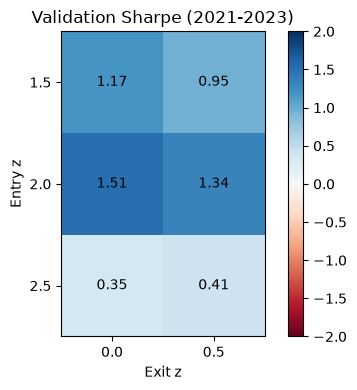

In [9]:
v = validation
mask = ((v["Selection Window"] == params["s"]) & (v["Estimation Window"] == params["n"])
        & (v["Stop Z"].fillna(-1) == (params["stop"] if params["stop"] is not None else -1))
        & (v["Max Hold"].fillna(-1) == (params["hold"] if params["hold"] is not None else -1)))
sens = v[mask].pivot(index="Entry Z", columns="Exit Z", values="Sharpe")

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(sens.to_numpy(dtype=float), cmap="RdBu", vmin=-2, vmax=2)
ax.set_xticks(range(len(sens.columns)), [str(c) for c in sens.columns])
ax.set_yticks(range(len(sens.index)), [str(i) for i in sens.index])
for i in range(sens.shape[0]):
    for j in range(sens.shape[1]):
        ax.text(j, i, f"{sens.iat[i, j]:.2f}", ha="center", va="center")
ax.set_xlabel("Exit z"); ax.set_ylabel("Entry z"); ax.set_title("Validation Sharpe (2021-2023)")
fig.colorbar(im, ax=ax); fig.tight_layout()
fig.savefig(OUT / "validation_entry_exit_heatmap.png", dpi=150)
plt.show()

## 第 9 步：测试阶段选股（截至 2023 年）
用同样的选股窗口长度，换成截至 2023-12-31 的数据**重新选一次股**（同样只在细分行业内）。

In [10]:
test_screen = sws.screen(prices, TEST_CUTOFF, params["s"])
test_chosen = sws.pick_pairs(test_screen)
test_chosen.to_csv(OUT / "test_pairs.csv", index=False)
test_pairs = list(zip(test_chosen["Ticker A"], test_chosen["Ticker B"]))
display(test_chosen[["Ticker A", "Ticker B", "Sub-Industry A", "P Value", "BH Adjusted P", "Selection Basis"]])

[cut2023_10Y] window 2014-2023: 2516 days, 430 tickers, universe=sub_industry, 1,082 pairs, 1,082 to test
[cut2023_10Y] 500/1,082 elapsed 40s
[cut2023_10Y] 1,000/1,082 elapsed 40s
[cut2023_10Y] 1,082/1,082 elapsed 40s
[cut2023_10Y] BH-significant pairs: 3


,Ticker A,Ticker B,Sub-Industry A,P Value,BH Adjusted P,Selection Basis
0,CDNS,SNPS,Application Software,9.073392e-07,0.000982,BH-significant
1,ADBE,CRM,Application Software,1.160949e-04,0.045339,BH-significant
2,GOOG,GOOGL,Interactive Media & Services,1.257083e-04,0.045339,BH-significant
3,MA,V,Transaction & Payment Processing Services,4.843125e-04,0.131007,Top-p fill (not BH-significant)
4,ABT,RMD,Health Care Equipment,1.288865e-03,0.257238,Top-p fill (not BH-significant)
5,DRI,YUM,Restaurants,1.713949e-03,0.257238,Top-p fill (not BH-significant)
6,ADI,MCHP,Semiconductors,1.832254e-03,0.257238,Top-p fill (not BH-significant)
7,GWW,HUBB,Industrial Machinery & Supplies & Components,2.348979e-03,0.257238,Top-p fill (not BH-significant)
8,BAC,PNC,Diversified Banks,2.660738e-03,0.257238,Top-p fill (not BH-significant)
9,JNJ,VTRS,Pharmaceuticals,2.690517e-03,0.257238,Top-p fill (not BH-significant)


## 第 10 步：样本外测试（2024–2026，只跑一次）
用冻结的参数分别跑验证期和测试期，做成样本内 vs 样本外对比表。

In [11]:
run_args = (params["n"], params["entry"], params["exit_"], params["stop"], params["hold"])
val_port, val_log, val_pr = sws.run_strategy(prices, val_pairs[params["s"]], VALIDATION_YEARS, *run_args, cost=COST)
test_port, test_log, test_pr = sws.run_strategy(prices, test_pairs, TEST_YEARS, *run_args, cost=COST)

is_oos = pd.DataFrame([
    {"Period": "验证 2021-2023（参数在这里选，算样本内）", **sws.summarize(val_port, val_log, val_pr)},
    {"Period": "测试 2024-2026（样本外）", **sws.summarize(test_port, test_log, test_pr)},
]).set_index("Period")
is_oos.to_csv(OUT / "in_sample_vs_out_of_sample.csv")
display(is_oos.T.round(3))

yearly = test_port.groupby(test_port.index.year).apply(lambda r: ((1 + r).prod() - 1) * 100)
skipped = test_pr[test_pr["Status"].ne("ok")]
if len(skipped):
    print("因对冲比例异常或数据不足而跳过的配对-年份:")
    display(skipped)
print("测试期每年收益 (%):")
display(yearly.round(2).rename("Return (%)").to_frame())

Period,验证 2021-2023（参数在这里选，算样本内）,测试 2024-2026（样本外）
Total Return (%),6.939,1.969
Annualized Return (%),2.271,0.682
Volatility (%),1.495,1.905
Sharpe,1.509,0.366
Max Drawdown (%),-1.678,-2.856
Trades,43.000,41.000
Win Rate (%),53.488,36.585
Avg Trade Return (%),1.614,0.377
Avg Annual Turnover,3.034,3.294
Top-5 Trades Share of P&L (%),55.701,197.568


因对冲比例异常或数据不足而跳过的配对-年份:


,Year,Pair,Status,Return (%),Trades,Turnover,Min Equity / Capital
9,2024,JNJ-VTRS,skipped: weak hedge (-0.07),NaN,NaN,NaN,NaN
19,2025,JNJ-VTRS,skipped: weak hedge (0.01),NaN,NaN,NaN,NaN
26,2026,ADI-MCHP,skipped: weak hedge (-0.11),NaN,NaN,NaN,NaN
29,2026,JNJ-VTRS,skipped: weak hedge (0.18),NaN,NaN,NaN,NaN


测试期每年收益 (%):


,Return (%)
Date,
2024,3.14
2025,-1.33
2026,0.20


## 第 11 步：组合净值曲线

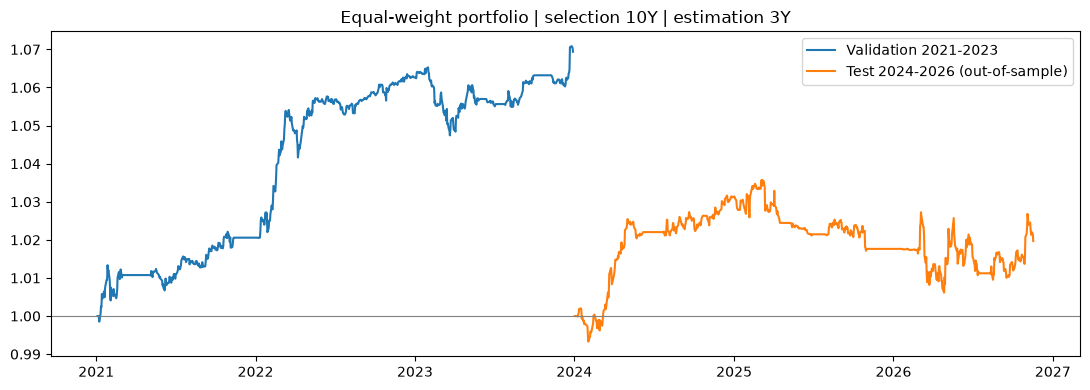

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot((1 + val_port).cumprod(), label="Validation 2021-2023")
ax.plot((1 + test_port).cumprod(), label="Test 2024-2026 (out-of-sample)")
ax.axhline(1, color="grey", lw=0.8)
ax.set_title(f"Equal-weight portfolio | selection {params['s']}Y | estimation {params['n']}Y")
ax.legend(); fig.tight_layout()
fig.savefig(OUT / "portfolio_equity_curve.png", dpi=150)
plt.show()

## 第 12 步：交易记录，利润是否集中在少数几笔？
`Contribution (%)` 是每笔交易对这一对当年收益的贡献。

In [13]:
test_log.to_csv(OUT / "test_trade_log.csv", index=False)
display(test_log[["Pair", "Year", "Entry Date", "Exit Date", "Direction", "Holding Days",
                  "Net P&L", "Trade Return (%)", "Contribution (%)", "Exit Reason"]].round(3))
print("各平仓原因次数:")
display(test_log["Exit Reason"].value_counts())
print("各配对总贡献 (%):")
display(test_log.groupby("Pair")["Contribution (%)"].sum().sort_values().round(2))

/var/folders/55/bpnz_y1d7h983b05s9zgmpbw0000gn/T/ipykernel_66451/2415232621.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "Net P&L", "Trade Return (%)", "Contribution (%)", "Exit Reason"]].round(3))


,Pair,Year,Entry Date,Exit Date,Direction,Holding Days,Net P&L,Trade Return (%),Contribution (%),Exit Reason
0,CDNS-SNPS,2024,2024-01-16,2024-01-19,-1,3,-11.777,-2.190,-2.275,Stop loss
1,CDNS-SNPS,2024,2024-07-23,2024-07-29,1,4,-4.219,-0.723,-0.815,Stop loss
2,CDNS-SNPS,2024,2024-09-10,2024-10-21,-1,29,22.170,4.492,4.282,Mean reversion
3,CDNS-SNPS,2024,2024-10-31,2024-11-06,-1,4,-1.553,-0.288,-0.300,Stop loss
4,ADBE-CRM,2024,2024-02-20,2024-02-23,1,3,-6.234,-0.509,-0.523,Stop loss
5,ADBE-CRM,2024,2024-09-23,2024-10-03,1,8,-66.413,-5.721,-5.577,Stop loss
6,MA-V,2024,2024-03-25,2024-06-07,-1,52,20.354,2.267,2.516,Mean reversion
7,MA-V,2024,2024-07-31,2024-08-02,-1,2,1.332,0.154,0.165,Stop loss
8,ABT-RMD,2024,2024-02-22,2024-04-29,-1,46,15.624,11.093,12.031,Mean reversion
9,DRI-YUM,2024,2024-01-09,2024-04-05,-1,60,13.404,4.698,4.693,Max holding


各平仓原因次数:


Exit Reason
Stop loss          26
Mean reversion      7
Max holding         6
End of backtest     2
Name: count, dtype: int64

各配对总贡献 (%):


Pair
BAC-PNC       -8.07
CDNS-SNPS     -7.05
ADBE-CRM      -2.92
GOOG-GOOGL    -0.91
ADI-MCHP      -0.04
MA-V           0.35
DRI-YUM        7.01
ABT-RMD       14.48
GWW-HUBB      14.93
Name: Contribution (%), dtype: float64

## 第 13 步：交易成本敏感性（测试集，只做展示，不用来选参数）
回答 PDF 里的 "Are profits destroyed by transaction costs?"。

In [14]:
cost_rows = []
for c in [0.0, 0.0005, 0.001, 0.002, 0.003]:
    p, l, r = sws.run_strategy(prices, test_pairs, TEST_YEARS, *run_args, cost=c)
    cost_rows.append({"单边成本 (bp)": c * 1e4, **sws.summarize(p, l, r)})
cost_table = pd.DataFrame(cost_rows)
cost_table.to_csv(OUT / "test_cost_sensitivity.csv", index=False)
display(cost_table[["单边成本 (bp)", "Annualized Return (%)", "Sharpe", "Max Drawdown (%)", "Trades"]].round(3))

,单边成本 (bp),Annualized Return (%),Sharpe,Max Drawdown (%),Trades
0,0.0,1.027,0.546,-2.603,41
1,5.0,0.854,0.456,-2.728,41
2,10.0,0.682,0.366,-2.856,41
3,20.0,0.338,0.186,-3.112,41
4,30.0,-0.005,0.007,-3.367,41


## 第 14 步：配对在测试期还协整吗？
回答 PDF 里的 "Do pairs remain cointegrated out of sample?"：只用 2024–26 的数据重新做 Engle-Granger 检验。

In [15]:
from statsmodels.tsa.stattools import coint
window = prices.loc[f"{TEST_YEARS[0]}-01-01":f"{TEST_YEARS[-1]}-12-31"]
persist = []
for a, b in test_pairs:
    d = window[[a, b]].dropna()
    p = float(coint(d[a], d[b], trend="c", autolag="aic")[1]) if len(d) > 100 else np.nan
    persist.append({"Pair": f"{a}-{b}", "测试期 EG p 值": p, "仍然 p<0.05": p < 0.05})
persist = pd.DataFrame(persist)
persist.to_csv(OUT / "test_cointegration_persistence.csv", index=False)
display(persist.round(4))

,Pair,测试期 EG p 值,仍然 p<0.05
0,CDNS-SNPS,0.0985,False
1,ADBE-CRM,0.3371,False
2,GOOG-GOOGL,0.1233,False
3,MA-V,0.1446,False
4,ABT-RMD,0.3704,False
5,DRI-YUM,0.0846,False
6,ADI-MCHP,0.9910,False
7,GWW-HUBB,0.9391,False
8,BAC-PNC,0.5814,False
9,JNJ-VTRS,0.4916,False


## 第 15 步：第一版 vs 第二版
把两版的样本内、样本外结果放在一起。第一版的结果来自 `selection_window_study_outputs/`。

In [16]:
v1_file = Path("selection_window_study_outputs/in_sample_vs_out_of_sample.csv")
if v1_file.exists():
    v1 = pd.read_csv(v1_file, index_col=0)
    v1.index = ["第一版 全市场 | " + ("验证" if ("验证" in i or "Validation" in i) else "测试") for i in v1.index]
    v2 = is_oos.copy()
    v2.index = ["第二版 细分行业 | " + ("验证" if ("验证" in i or "Validation" in i) else "测试") for i in v2.index]
    cols = ["Annualized Return (%)", "Sharpe", "Max Drawdown (%)", "Trades", "Win Rate (%)"]
    display(pd.concat([v1, v2])[cols].round(3))
else:
    print("没找到第一版结果文件")

,Annualized Return (%),Sharpe,Max Drawdown (%),Trades,Win Rate (%)
第一版 全市场 | 验证,3.461,1.041,-3.404,68,48.529
第一版 全市场 | 测试,-0.508,-0.151,-6.196,64,43.750
第二版 细分行业 | 验证,2.271,1.509,-1.678,43,53.488
第二版 细分行业 | 测试,0.682,0.366,-2.856,41,36.585


## 跑完之后
所有结果都在 `selection_window_study_outputs_v2/` 文件夹里。最值得先看的三份：
- `validation_by_selection_window.csv`：哪种选股窗口更好（第 6 步）
- `in_sample_vs_out_of_sample.csv`：验证 vs 测试（第 10 步）
- `test_cointegration_persistence.csv`：配对在测试期是否还协整（第 14 步）